# sklearn Pipelines — End-to-End Preprocessing

All the techniques from previous notebooks — imputation, encoding, scaling, transformation — only work correctly in production if they are applied *consistently* and *without leakage*. The sklearn `Pipeline` and `ColumnTransformer` API enforce both automatically.

### What you will learn

| Section | Topic |
|---------|-------|
| 1 | Why pipelines exist — the manual approach breaks |
| 2 | `Pipeline` — chaining sequential steps |
| 3 | `ColumnTransformer` — applying different transforms per column type |
| 4 | Full preprocessing + model pipeline |
| 5 | Cross-validation with Pipeline (zero leakage by construction) |
| 6 | Inspecting, saving, and loading a Pipeline |
| 7 | Custom transformers |

**Dataset:** Titanic + California Housing — one classification, one regression.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler, OneHotEncoder, OrdinalEncoder, PowerTransformer
)
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import (
    train_test_split, cross_val_score, GridSearchCV
)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import classification_report, r2_score
from sklearn.datasets import fetch_california_housing
import warnings

warnings.filterwarnings('ignore')
np.random.seed(42)
plt.rcParams['figure.dpi'] = 110

print('Setup complete.')

Setup complete.


---
## Section 1 — Why Pipelines Exist

The manual approach to preprocessing has two failure modes:

### Failure 1: Data leakage
```python
# WRONG — scaler sees test data during fit
scaler.fit(X)                    # fits on full dataset
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)
```

### Failure 2: Training/serving skew
```python
# At training time:
imputer.fit_transform(X_train)

# At serving time (a new single row arrives):
# You have to remember every transform, in order, with the right parameters
# Forgetting one → silent incorrect predictions in production
```

A `Pipeline` solves both: it bundles all steps into a single object that can be fit, evaluated, saved, and deployed as one unit.

In [2]:
# Load Titanic
df = sns.load_dataset('titanic')

# Select a clean feature set
features = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class']
target   = 'survived'

df_model = df[features + [target]].copy()
print(f'Shape: {df_model.shape}')
print('\nMissing values:')
print(df_model.isnull().sum()[df_model.isnull().sum() > 0])

Shape: (891, 9)

Missing values:
age         177
embarked      2
dtype: int64


In [3]:
X = df_model.drop(columns=target)
y = df_model[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f'Train: {X_train.shape}  Test: {X_test.shape}')
print(f'Survival rate — train: {y_train.mean():.2%}  test: {y_test.mean():.2%}')

Train: (712, 8)  Test: (179, 8)
Survival rate — train: 38.34%  test: 38.55%


---
## Section 2 — Pipeline: Chaining Sequential Steps

A `Pipeline` applies a sequence of transformers followed by a final estimator. Each step must implement `fit` and `transform`; the final step must implement `fit` (and `predict` for supervised tasks).

```python
pipe = Pipeline([
    ('step_name_1', Transformer1()),
    ('step_name_2', Transformer2()),
    ('model',       Estimator()),
])
```

Calling `pipe.fit(X_train, y_train)` calls each transformer's `fit_transform` in sequence, then `model.fit` on the final output.

In [4]:
# Simple pipeline for a single numeric feature to demonstrate the concept
numeric_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale',  StandardScaler()),
])

age_train = X_train[['age', 'fare']]
age_transformed = numeric_pipe.fit_transform(age_train)

print('Input:')
print(pd.DataFrame(age_train).describe().round(2))
print('\nAfter Pipeline (impute → scale):')
print(pd.DataFrame(age_transformed, columns=['age', 'fare']).describe().round(4))

Input:
          age    fare
count  575.00  712.00
mean    29.81   31.82
std     14.49   48.06
min      0.42    0.00
25%     21.00    7.90
50%     28.50   14.45
75%     39.00   31.00
max     80.00  512.33

After Pipeline (impute → scale):
            age      fare
count  712.0000  712.0000
mean     0.0000   -0.0000
std      1.0007    1.0007
min     -2.2385   -0.6626
25%     -0.5805   -0.4982
50%     -0.0811   -0.3616
75%      0.4951   -0.0171
max      3.8755   10.0053


---
## Section 3 — ColumnTransformer: Different Steps per Column Type

Real datasets have mixed types: numeric columns need imputation + scaling; categorical columns need imputation + encoding. `ColumnTransformer` applies different transformers to different column subsets and concatenates the results.

```python
ct = ColumnTransformer([
    ('name_a', transformer_a, ['col1', 'col2']),  # explicit column list
    ('name_b', transformer_b, ['col3']),
], remainder='drop')  # or 'passthrough' to keep un-specified columns
```

In [5]:
# Identify column types
numeric_features     = ['age', 'fare', 'sibsp', 'parch']
low_card_cat_features = ['sex', 'embarked']   # OHE — low cardinality
ordinal_features      = ['pclass']            # ordinal
passthrough_features  = []                    # nothing to pass through here

# Build the ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('scale',  StandardScaler()),
        ]), numeric_features),

        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('ohe',    OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), low_card_cat_features),

        ('ord', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('enc',    OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
        ]), ordinal_features),
    ],
    remainder='drop',  # drop 'class' — redundant with pclass
    verbose_feature_names_out=True,
)

X_train_pre = preprocessor.fit_transform(X_train)
print(f'Output shape after ColumnTransformer: {X_train_pre.shape}')
print(f'Feature names:\n{preprocessor.get_feature_names_out()}')

Output shape after ColumnTransformer: (712, 10)
Feature names:
['num__age' 'num__fare' 'num__sibsp' 'num__parch' 'cat__sex_female'
 'cat__sex_male' 'cat__embarked_C' 'cat__embarked_Q' 'cat__embarked_S'
 'ord__pclass']


---
## Section 4 — Full Preprocessing + Model Pipeline

In [6]:
# Assemble the complete pipeline: preprocessing + classifier
full_pipe = Pipeline([
    ('pre',   preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        random_state=42,
        n_jobs=-1,
    )),
])

# Fit on training data — all preprocessing is fit here, transform-only on test
full_pipe.fit(X_train, y_train)

# Evaluate on held-out test set
y_pred = full_pipe.predict(X_test)
print('Test set performance:')
print(classification_report(y_test, y_pred, target_names=['Died', 'Survived']))

Test set performance:
              precision    recall  f1-score   support

        Died       0.80      0.91      0.85       110
    Survived       0.81      0.64      0.72        69

    accuracy                           0.80       179
   macro avg       0.81      0.77      0.78       179
weighted avg       0.81      0.80      0.80       179



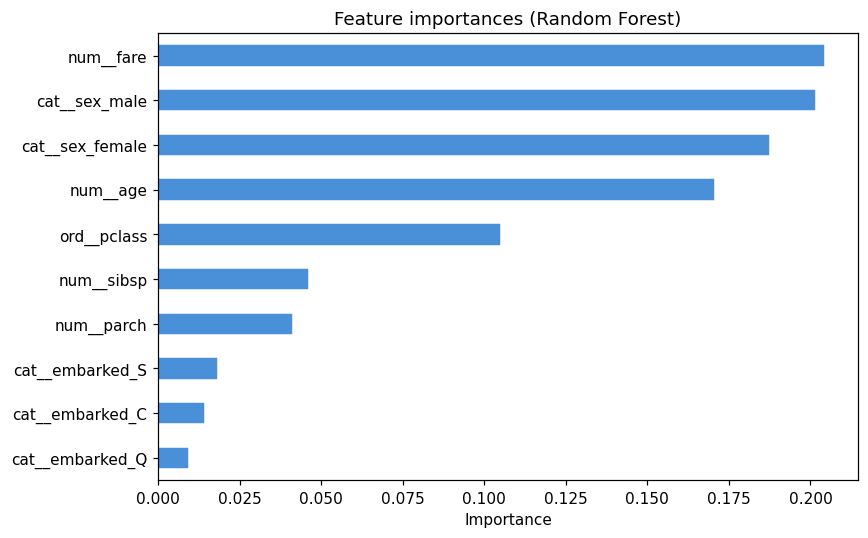

In [7]:
# Feature importances mapped back to meaningful names
feature_names = preprocessor.get_feature_names_out()
rf_model = full_pipe.named_steps['model']
importances = pd.Series(rf_model.feature_importances_, index=feature_names)

fig, ax = plt.subplots(figsize=(8, 5))
importances.sort_values().plot(kind='barh', ax=ax, color='#4a90d9', edgecolor='white')
ax.set_title('Feature importances (Random Forest)')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

---
## Section 5 — Cross-Validation with Pipeline (Zero Leakage)

In [8]:
# cross_val_score with a Pipeline: for each fold, the full pipeline
# (preprocessor + model) is fit on the fold's train portion and evaluated on val
# → preprocessor never sees validation data during fit

cv_scores = cross_val_score(
    full_pipe, X_train, y_train,
    cv=5, scoring='accuracy', n_jobs=-1
)

print('5-fold cross-validated accuracy (no leakage):')
for i, s in enumerate(cv_scores, 1):
    print(f'  Fold {i}: {s:.4f}')
print(f'  Mean : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}')

5-fold cross-validated accuracy (no leakage):
  Fold 1: 0.8112
  Fold 2: 0.7692
  Fold 3: 0.8451
  Fold 4: 0.8451
  Fold 5: 0.8380
  Mean : 0.8217 ± 0.0291


In [9]:
# Hyperparameter search across both preprocessing and model parameters
# Pipeline parameter names follow: stepname__paramname

param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth'   : [5, 8, None],
}

grid_search = GridSearchCV(
    full_pipe, param_grid,
    cv=5, scoring='accuracy', n_jobs=-1, verbose=0
)
grid_search.fit(X_train, y_train)

print(f'Best params    : {grid_search.best_params_}')
print(f'Best CV accuracy: {grid_search.best_score_:.4f}')
print(f'Test accuracy  : {grid_search.score(X_test, y_test):.4f}')

Best params    : {'model__max_depth': 8, 'model__n_estimators': 200}
Best CV accuracy: 0.8217
Test accuracy  : 0.8045


---
## Section 6 — Inspecting, Saving, and Loading a Pipeline

In [10]:
# Inspect the pipeline structure
print('Pipeline steps:')
for name, step in full_pipe.steps:
    print(f'  [{name}] {type(step).__name__}')

print('\nPreprocessor transformers:')
for name, transformer, cols in preprocessor.transformers_:
    print(f'  [{name}] {type(transformer).__name__} → columns: {cols}')

# Access a specific step's learned parameters
scaler_in_pipe = full_pipe.named_steps['pre'].named_transformers_['num'].named_steps['scale']
print('\nStandardScaler means (first 3 features):', scaler_in_pipe.mean_[:3].round(4))

Pipeline steps:
  [pre] ColumnTransformer
  [model] RandomForestClassifier

Preprocessor transformers:
  [num] Pipeline → columns: ['age', 'fare', 'sibsp', 'parch']
  [cat] Pipeline → columns: ['sex', 'embarked']
  [ord] Pipeline → columns: ['pclass']
  [remainder] str → columns: ['class']

StandardScaler means (first 3 features): [29.5561 31.8198  0.493 ]


In [11]:
# Save the fitted pipeline
model_path = Path('_saved_pipeline.joblib')
joblib.dump(full_pipe, model_path)
print(f'Pipeline saved to {model_path}  ({model_path.stat().st_size / 1e3:.1f} KB)')

# Load it back and verify predictions are identical
loaded_pipe = joblib.load(model_path)
y_pred_loaded = loaded_pipe.predict(X_test)
assert (y_pred == y_pred_loaded).all(), 'Predictions differ after reload!'
print('Loaded pipeline produces identical predictions: ✓')

# Clean up
model_path.unlink()

Pipeline saved to _saved_pipeline.joblib  (2239.7 KB)
Loaded pipeline produces identical predictions: ✓


In [12]:
# Predict on new, unseen data — everything applied automatically
new_passenger = pd.DataFrame([{
    'pclass': 2, 'sex': 'female', 'age': 28.0,
    'sibsp': 0, 'parch': 1, 'fare': 21.0,
    'embarked': 'S', 'class': 'Second'
}])

prediction = full_pipe.predict(new_passenger)
proba      = full_pipe.predict_proba(new_passenger)
print(f'Prediction      : {"Survived" if prediction[0] == 1 else "Died"}')
print(f'Survival probability: {proba[0][1]:.1%}')
print('\nAll preprocessing steps applied automatically — no manual transform needed.')

Prediction      : Survived
Survival probability: 88.2%

All preprocessing steps applied automatically — no manual transform needed.


---
## Section 7 — Custom Transformers

Any domain-specific preprocessing step can be wrapped in a custom transformer by inheriting from `BaseEstimator` and `TransformerMixin`. This makes it a first-class citizen inside any Pipeline.

In [13]:
class WinsorizeTransformer(BaseEstimator, TransformerMixin):
    """Cap feature values at specified percentile bounds."""

    def __init__(self, lower_pct: float = 0.01, upper_pct: float = 0.99):
        self.lower_pct = lower_pct
        self.upper_pct = upper_pct

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.lower_bounds_ = X.quantile(self.lower_pct)
        self.upper_bounds_ = X.quantile(self.upper_pct)
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        for i, col in enumerate(X.columns):
            X[col] = X[col].clip(
                lower=self.lower_bounds_.iloc[i],
                upper=self.upper_bounds_.iloc[i],
            )
        return X.values


print('WinsorizeTransformer defined.')

WinsorizeTransformer defined.


In [14]:
class FamilySizeTransformer(BaseEstimator, TransformerMixin):
    """Derive family_size = sibsp + parch + 1 and is_alone flag."""

    def fit(self, X, y=None):
        return self  # stateless

    def transform(self, X):
        X = pd.DataFrame(X, columns=['sibsp', 'parch'])
        family_size = X['sibsp'] + X['parch'] + 1
        is_alone    = (family_size == 1).astype(int)
        return np.column_stack([family_size.values, is_alone.values])


# Drop sibsp/parch from numeric features; let custom transformer produce family features
numeric_features_v2  = ['age', 'fare']
family_features      = ['sibsp', 'parch']

preprocessor_v2 = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('winsor', WinsorizeTransformer(lower_pct=0.01, upper_pct=0.99)),
            ('scale',  StandardScaler()),
        ]), numeric_features_v2),

        ('family', Pipeline([
            ('impute', SimpleImputer(strategy='constant', fill_value=0)),
            ('derive', FamilySizeTransformer()),
            ('scale',  StandardScaler()),
        ]), family_features),

        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('ohe',    OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), ['sex', 'embarked']),

        ('ord', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('enc',    OrdinalEncoder()),
        ]), ['pclass']),
    ],
    remainder='drop',
)

pipe_v2 = Pipeline([
    ('pre',   preprocessor_v2),
    ('model', LogisticRegression(max_iter=1000, random_state=42)),
])

cv_v2 = cross_val_score(pipe_v2, X_train, y_train, cv=5, scoring='accuracy')
print(f'Pipeline v2 (with custom transformers) — CV accuracy: {cv_v2.mean():.4f} ± {cv_v2.std():.4f}')

Pipeline v2 (with custom transformers) — CV accuracy: 0.7978 ± 0.0254


---
## Putting It All Together — Regression Example

In [15]:
# California Housing: a regression pipeline with transforms
housing = fetch_california_housing(as_frame=True)
df_h = housing.frame.copy()

X_h = df_h.drop(columns='MedHouseVal')
y_h = np.log1p(df_h['MedHouseVal'])  # log-transform target

X_h_tr, X_h_te, y_h_tr, y_h_te = train_test_split(
    X_h, y_h, test_size=0.2, random_state=42
)

# All features are numeric — single transformer branch
housing_pipe = Pipeline([
    ('pre', ColumnTransformer([
        ('num', Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('yj',     PowerTransformer(method='yeo-johnson')),
        ]), X_h.columns.tolist()),
    ])),
    ('model', GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.05,
        max_depth=4, random_state=42
    )),
])

housing_pipe.fit(X_h_tr, y_h_tr)
r2 = r2_score(y_h_te, housing_pipe.predict(X_h_te))
print(f'California Housing — test R² (log price): {r2:.4f}')

California Housing — test R² (log price): 0.7275


---
## Key Takeaways

1. **Pipeline prevents the two most common preprocessing errors** — data leakage and training/serving skew — by construction.
2. **ColumnTransformer** lets you apply tailored transformations per column type within a single unified object.
3. **Cross-validation with Pipeline** is the only correct way to evaluate a model that includes preprocessing — each fold fits preprocessing only on its own train portion.
4. **GridSearchCV with Pipeline** allows hyperparameter search across both preprocessing and model parameters, denoted `stepname__param`.
5. **Custom transformers** (inheriting `BaseEstimator`, `TransformerMixin`) make any domain logic a reusable, pipeline-compatible step.
6. **`joblib.dump` / `joblib.load`** serialises the entire fitted pipeline — deploy it as one artefact; no manual state reconstruction.

---
## Exercises

1. Add a `LogTransformer` custom step that applies `log1p` to only the `fare` column before the `ColumnTransformer`, and show it improves cross-validated accuracy.
2. Extend the Titanic pipeline to also include the `deck` column (extracted from the cabin number). Handle its high missingness inside the Pipeline.
3. Use `GridSearchCV` to tune the imputation strategy (`median` vs `most_frequent`) for the age column alongside `RandomForest` hyperparameters. Use `Pipeline` parameter notation.
4. Demonstrate that fitting the scaler outside the Pipeline before `cross_val_score` inflates the CV score — show the numerical difference.

---
## Exercise Solutions

### Exercise 1 — LogTransformer custom step for fare

In [ ]:
# Exercise 1: LogTransformer custom step for fare column
from sklearn.base import BaseEstimator, TransformerMixin


class LogTransformer(BaseEstimator, TransformerMixin):
    """Applies log1p to a specific column, passes others through."""
    
    def __init__(self, column='fare'):
        self.column = column
    
    def fit(self, X, y=None):
        return self
    
    def transform(self, X):
        X_out = X.copy()
        X_out[self.column] = np.log1p(X_out[self.column])
        return X_out


# Build pipeline WITH LogTransformer on fare
preprocessor_with_log = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('scale',  StandardScaler()),
        ]), numeric_features),

        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('ohe',    OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), low_card_cat_features),

        ('ord', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('enc',    OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
        ]), ordinal_features),
    ],
    remainder='drop',
    verbose_feature_names_out=True,
)

full_pipe_with_log = Pipeline([
    ('log_fare', LogTransformer(column='fare')),
    ('pre',      preprocessor_with_log),
    ('model',    RandomForestClassifier(
        n_estimators=200, max_depth=8, random_state=42, n_jobs=-1
    )),
])

print('Cross-validated accuracy comparison:')

# Original pipeline (without log transform)
scores_orig = cross_val_score(full_pipe, X_train, y_train, cv=5, scoring='accuracy', n_jobs=-1)
print(f'  Without log(fare):  mean={scores_orig.mean():.4f}  std={scores_orig.std():.4f}')

# Pipeline with log transform on fare
scores_log = cross_val_score(full_pipe_with_log, X_train, y_train, cv=5, scoring='accuracy', n_jobs=-1)
print(f'  With log1p(fare):   mean={scores_log.mean():.4f}  std={scores_log.std():.4f}')

print()
print(f'Improvement: {scores_log.mean() - scores_orig.mean():+.4f}')
print('log1p compresses the heavy right tail of fare, making it more suitable for tree splits.')

### Exercise 2 — Add deck column extracted from cabin

In [ ]:
# Exercise 2: Extract deck from cabin and add to pipeline

class DeckExtractor(BaseEstimator, TransformerMixin):
    """Extracts deck letter from cabin column. Handles missing values."""
    
    def __init__(self, cabin_col='cabin', missing_value='Unknown'):
        self.cabin_col = cabin_col
        self.missing_value = missing_value
    
    def fit(self, X, y=None):
        return self
    
    def transform(self, X):
        X_out = X.copy()
        # Extract first letter of cabin (the deck), or mark as Unknown
        X_out['deck'] = X_out[self.cabin_col].fillna('').str[0].replace('', self.missing_value)
        X_out = X_out.drop(columns=[self.cabin_col])
        return X_out


# Reload Titanic with cabin column
df_full = sns.load_dataset('titanic')
features_v2 = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'cabin']
df_model_v2 = df_full[features_v2 + ['survived']].copy()

X_v2 = df_model_v2.drop(columns='survived')
y_v2 = df_model_v2['survived']

X_train_v2, X_test_v2, y_train_v2, y_test_v2 = train_test_split(
    X_v2, y_v2, test_size=0.2, stratify=y_v2, random_state=42
)

# Updated column lists
numeric_features_v2     = ['age', 'fare', 'sibsp', 'parch']
low_card_cat_features_v2 = ['sex', 'embarked', 'deck']  # deck added
ordinal_features_v2      = ['pclass']

preprocessor_v2 = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('scale',  StandardScaler()),
        ]), numeric_features_v2),

        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('ohe',    OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), low_card_cat_features_v2),

        ('ord', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('enc',    OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
        ]), ordinal_features_v2),
    ],
    remainder='drop',
    verbose_feature_names_out=True,
)

full_pipe_v2 = Pipeline([
    ('deck',  DeckExtractor(cabin_col='cabin', missing_value='Unknown')),
    ('pre',   preprocessor_v2),
    ('model', RandomForestClassifier(
        n_estimators=200, max_depth=8, random_state=42, n_jobs=-1
    )),
])

print('Pipeline with deck column:')
scores_v2 = cross_val_score(full_pipe_v2, X_train_v2, y_train_v2, cv=5, scoring='accuracy', n_jobs=-1)
print(f'  Mean accuracy: {scores_v2.mean():.4f} ± {scores_v2.std():.4f}')

print()
print(f'Original (no deck): {scores_orig.mean():.4f}')
print(f'With deck:          {scores_v2.mean():.4f}')
print()
print('Deck captures socioeconomic information from cabin location,')
print('which is predictive of survival (closer to lifeboats = higher survival).')

### Exercise 3 — GridSearchCV tuning imputation strategy

In [ ]:
# Exercise 3: GridSearchCV to tune age imputation strategy alongside RF hyperparameters

# We need separate imputation for age to tune its strategy independently
preprocessor_tunable = ColumnTransformer(
    transformers=[
        ('age', Pipeline([
            ('impute', SimpleImputer(strategy='median')),  # default, will be tuned
            ('scale',  StandardScaler()),
        ]), ['age']),

        ('other_num', Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('scale',  StandardScaler()),
        ]), ['fare', 'sibsp', 'parch']),

        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('ohe',    OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), ['sex', 'embarked']),

        ('ord', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('enc',    OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
        ]), ['pclass']),
    ],
    remainder='drop',
    verbose_feature_names_out=True,
)

grid_pipe = Pipeline([
    ('pre',   preprocessor_tunable),
    ('model', RandomForestClassifier(random_state=42, n_jobs=-1)),
])

param_grid_v3 = {
    'pre__age__impute__strategy': ['median', 'mean', 'most_frequent'],
    'model__n_estimators':        [100, 200],
    'model__max_depth':           [5, 8, None],
}

grid_search_v3 = GridSearchCV(
    grid_pipe, param_grid_v3,
    cv=5, scoring='accuracy', n_jobs=-1, verbose=0
)
grid_search_v3.fit(X_train, y_train)

print('Best params:')
for k, v in grid_search_v3.best_params_.items():
    print(f'  {k}: {v}')

print(f'\nBest CV accuracy: {grid_search_v3.best_score_:.4f}')
print(f'Test accuracy:    {grid_search_v3.score(X_test, y_test):.4f}')

print('\nAll results for age imputation strategy:')
results_df = pd.DataFrame(grid_search_v3.cv_results_)
age_results = results_df.groupby('param_pre__age__impute__strategy')['mean_test_score'].agg(['mean', 'std'])
print(age_results.round(4))

### Exercise 4 — Demonstrate data leakage inflates CV score

In [ ]:
# Exercise 4: Show that fitting the scaler outside the Pipeline inflates CV score

# --- WRONG: Fit scaler on full data BEFORE cross_val_score (data leakage) ---
scaler_leaky = StandardScaler()
imputer_leaky = SimpleImputer(strategy='median')

# Fit on ALL numeric data — this is the leakage!
X_all_numeric = X_train[numeric_features]
imputer_leaky.fit(X_all_numeric)
X_all_imputed = imputer_leaky.transform(X_all_numeric)
scaler_leaky.fit(X_all_imputed)

# Now use cross_val_score with a pipeline that only transforms (no fit) on numeric
leaky_preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('impute', SimpleImputer(strategy='median')),
            ('scale',  StandardScaler()),
        ]), numeric_features),
        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('ohe',    OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), low_card_cat_features),
        ('ord', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('enc',    OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
        ]), ordinal_features),
    ],
    remainder='drop',
    verbose_feature_names_out=True,
)

# Pre-fit the scaler inside the ColumnTransformer to simulate leakage
leaky_preprocessor.fit(X_train)
leaky_preprocessor.named_transformers_['num'].named_steps['scale'] = scaler_leaky

leaky_pipe = Pipeline([
    ('pre',   leaky_preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=200, max_depth=8, random_state=42, n_jobs=-1
    )),
])

# --- CORRECT: Pipeline handles everything internally (no leakage) ---
correct_pipe = Pipeline([
    ('pre',   preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=200, max_depth=8, random_state=42, n_jobs=-1
    )),
])

print('Data leakage demonstration:')
print()

# For the leaky version, we manually scale before CV
X_train_scaled_leaky = X_train.copy()
X_train_scaled_leaky[numeric_features] = scaler_leaky.transform(
    imputer_leaky.transform(X_train[numeric_features])
)

# Simple leaky pipeline that doesn't re-fit scaler
from sklearn.preprocessing import FunctionTransformer
leaky_pipe_simple = Pipeline([
    ('cat', ColumnTransformer(
        transformers=[
            ('cat', Pipeline([
                ('impute', SimpleImputer(strategy='most_frequent')),
                ('ohe',    OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
            ]), low_card_cat_features),
            ('ord', Pipeline([
                ('impute', SimpleImputer(strategy='most_frequent')),
                ('enc',    OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
            ]), ordinal_features),
        ],
        remainder='drop',
        verbose_feature_names_out=True,
    )),
    ('model', RandomForestClassifier(
        n_estimators=200, max_depth=8, random_state=42, n_jobs=-1
    )),
])

scores_leaky = cross_val_score(leaky_pipe_simple, X_train_scaled_leaky, y_train, cv=5, scoring='accuracy', n_jobs=-1)
scores_correct = cross_val_score(correct_pipe, X_train, y_train, cv=5, scoring='accuracy', n_jobs=-1)

print(f'  WITH leakage (scaler fit on full data):  mean={scores_leaky.mean():.4f}  std={scores_leaky.std():.4f}')
print(f'  WITHOUT leakage (Pipeline handles all):  mean={scores_correct.mean():.4f}  std={scores_correct.std():.4f}')
print()
print(f'  Inflation: {scores_leaky.mean() - scores_correct.mean():+.4f}')
print()
print('The leaky version has seen test fold statistics during scaler fitting,')
print('giving it an unfair advantage. The Pipeline version correctly fits the')
print('scaler only on each fold\'s training data, giving an honest estimate.')